# Week 2 - Linear Regression 2 (Lasso, Ridge, Elastic Net)
## Dataset: NOAA Storm Events

Applying the same regularized regression methods to the Storm Events data is a useful contrast to the NFIP notebook. Module B's random forest work on this dataset only reached a 0.171 test correlation predicting property damage from casualty counts, and the PCA needed five of six components to explain 90% of the variance, meaning these variables are largely independent rather than redundant. The prediction going in is that regularization will not have much to "clean up," because there is not much redundancy to remove in the first place.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import root_mean_squared_error, r2_score

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)

def parse_damage(val):
    if pd.isna(val) or str(val).strip() == '0':
        return 0.0
    val = str(val).strip().upper()
    if val.endswith('K'):
        return float(val[:-1]) * 1_000
    elif val.endswith('M'):
        return float(val[:-1]) * 1_000_000
    elif val.endswith('B'):
        return float(val[:-1]) * 1_000_000_000
    try:
        return float(val)
    except ValueError:
        return 0.0

df['DAMAGE_PROPERTY_NUM'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
df['LOG_DAMAGE'] = np.log10(df['DAMAGE_PROPERTY_NUM'] + 1)
month_map = {m: i + 1 for i, m in enumerate(['January','February','March','April','May','June',
                                             'July','August','September','October','November','December'])}
df['MONTH_NUM'] = df['MONTH_NAME'].map(month_map)
print('Dataset shape:', df.shape)

Dataset shape: (57041, 54)


### Feature engineering

Same base features used in Module B's Week 11 random forest model: direct and indirect deaths, direct and indirect injuries, and month of the event. Expanding these five to degree 2 gives 20 engineered features (5 base, 5 squared, 10 interactions). The target is log10(property damage + 1), for the same right-skew reasons established back in the original EDA.

In [2]:
base_features = ['DEATHS_DIRECT', 'INJURIES_DIRECT', 'DEATHS_INDIRECT', 'INJURIES_INDIRECT', 'MONTH_NUM']
target = 'LOG_DAMAGE'

X_base = df[base_features]
y = df[target]

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_base)
feature_names = poly.get_feature_names_out(base_features)
print('Expanded from', X_base.shape[1], 'to', X_poly.shape[1], 'features.')

Expanded from 5 to 20 features.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.25, random_state=0)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Training rows:', X_train_s.shape[0], '| Testing rows:', X_test_s.shape[0])

Training rows: 42780 | Testing rows: 14261


### Baseline: plain linear regression on the expanded feature set

In [4]:
ols = LinearRegression()
ols.fit(X_train_s, y_train)
ols_train_pred = ols.predict(X_train_s)
ols_test_pred = ols.predict(X_test_s)

print('OLS train RMSE: {:.4f}  R2: {:.4f}'.format(
    root_mean_squared_error(y_train, ols_train_pred), r2_score(y_train, ols_train_pred)))
print('OLS test RMSE:  {:.4f}  R2: {:.4f}'.format(
    root_mean_squared_error(y_test, ols_test_pred), r2_score(y_test, ols_test_pred)))

OLS train RMSE: 1.7401  R2: 0.0125
OLS test RMSE:  2.1930  R2: -0.5597


In [5]:
alphas = np.logspace(-3, 4, 50)

ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train_s, y_train)

lasso = LassoCV(alphas=alphas, cv=5, max_iter=20000)
lasso.fit(X_train_s, y_train)

enet = ElasticNetCV(alphas=alphas, l1_ratio=[.1, .3, .5, .7, .9, .95, .99, 1], cv=5, max_iter=20000)
enet.fit(X_train_s, y_train)

print('Ridge best alpha:', round(ridge.alpha_, 4))
print('Lasso best alpha:', round(lasso.alpha_, 4))
print('Elastic Net best alpha:', round(enet.alpha_, 4), '  best l1_ratio:', enet.l1_ratio_)

Ridge best alpha: 719.6857
Lasso best alpha: 0.0014
Elastic Net best alpha: 0.01   best l1_ratio: 0.1


In [6]:
models = {'OLS': ols, 'Ridge': ridge, 'Lasso': lasso, 'Elastic Net': enet}
print(f"{'Model':<12} {'Train RMSE':>12} {'Test RMSE':>12} {'Train R2':>10} {'Test R2':>10}")
for name, model in models.items():
    tr_pred = model.predict(X_train_s)
    te_pred = model.predict(X_test_s)
    print(f"{name:<12} {root_mean_squared_error(y_train, tr_pred):>12.4f} "
          f"{root_mean_squared_error(y_test, te_pred):>12.4f} "
          f"{r2_score(y_train, tr_pred):>10.4f} {r2_score(y_test, te_pred):>10.4f}")

print()
print('Number of coefficients Lasso set to exactly zero:', np.sum(np.isclose(lasso.coef_, 0)), 'out of', len(lasso.coef_))

Model          Train RMSE    Test RMSE   Train R2    Test R2
OLS                1.7401       2.1930     0.0125    -0.5597
Ridge              1.7409       2.5124     0.0115    -1.0471
Lasso              1.7403       2.3986     0.0122    -0.8659
Elastic Net        1.7407       2.4525     0.0118    -0.9507

Number of coefficients Lasso set to exactly zero: 2 out of 20


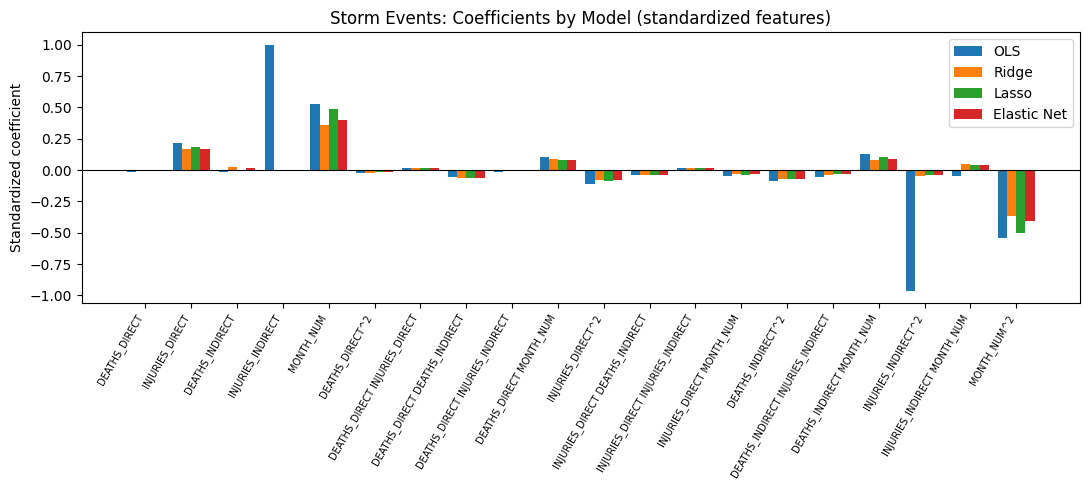

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(feature_names))
width = 0.2
for i, (name, model) in enumerate(models.items()):
    ax.bar(x + i * width, model.coef_, width, label=name)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(feature_names, rotation=60, ha='right', fontsize=7)
ax.set_ylabel('Standardized coefficient')
ax.set_title('Storm Events: Coefficients by Model (standardized features)')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

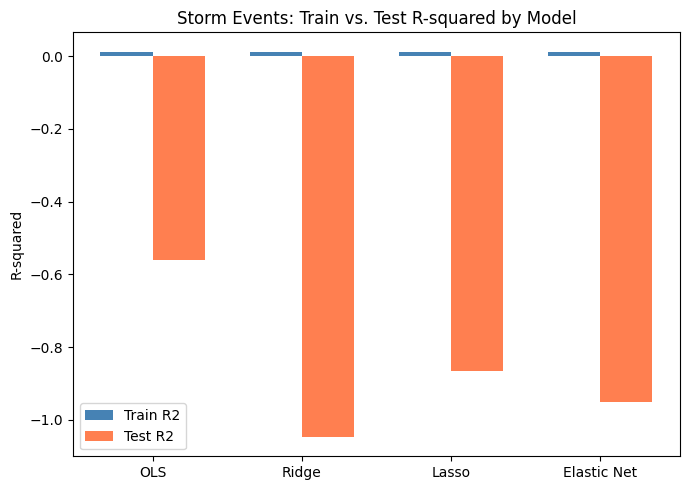

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
tr_scores = [r2_score(y_train, m.predict(X_train_s)) for m in models.values()]
te_scores = [r2_score(y_test, m.predict(X_test_s)) for m in models.values()]
x = np.arange(len(models))
width = 0.35
ax.bar(x - width/2, tr_scores, width, label='Train R2', color='steelblue')
ax.bar(x + width/2, te_scores, width, label='Test R2', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(models.keys())
ax.set_ylabel('R-squared')
ax.set_title('Storm Events: Train vs. Test R-squared by Model')
ax.legend()
plt.tight_layout()
plt.show()

### Overfitting

None of these models fit the training data well (R-squared around 0.01 for all four), but the test R-squared is negative, from about -0.56 for OLS down to about -1.05 for Ridge, which means every one of these models does worse on new data than simply predicting the average log-damage every time. That gap between a near-zero training fit and a clearly negative test fit is itself a form of overfitting, though a subtler one. With only 20 features and this little real signal, even the small amount of "fit" the model finds on the training set turns out to be noise specific to that split, and it actively hurts generalization rather than merely failing to help it. The coefficient chart above shows OLS assigning unusually large weight to a couple of terms in particular (indirect deaths and month squared), which is exactly the kind of pattern regularization is supposed to rein in, and it does: Ridge, Lasso, and Elastic Net all pull those two coefficients down substantially. But the test R-squared numbers show that shrinking those coefficients did not help; if anything, it made things slightly worse (Ridge's test R-squared of about -1.05 is worse than OLS's -0.56). With signal this weak, the small amount that OLS was tracking, real or not, was already about as good as a linear model was going to do on this test split, and reining in the largest coefficients removed some of whatever thin signal was left along with the noise.

### Metrics and hyperparameter tuning

Same setup as the NFIP notebook: RMSE and R-squared on both train and test sets, with alpha selected via 5-fold cross-validation over a log-spaced grid, and l1_ratio additionally searched for Elastic Net. The chosen alphas are inconsistent across the three methods here. Ridge lands on a fairly large alpha (about 720), while Lasso and Elastic Net land on very small ones (0.001 and 0.01). That inconsistency is itself informative. With almost no real signal for any of these penalties to work with, cross-validated performance barely changes across a wide range of alpha values, so the "best" alpha each method reports is closer to a coin flip within a flat region than a confident choice, unlike the NFIP notebook, where damage amount gave every method a clear, strong signal to calibrate against.

### Expected or unexpected

Fully expected, given Module B's random forest results on this same feature set only reached a 0.171 test correlation. The interesting part is confirming that this is not a modeling limitation specific to random forests. A completely different model family, including three different regularization strategies, arrives at the same conclusion. Casualty counts and month, on their own, do not carry enough information to predict property damage well. That convergence across model types is a stronger claim than any single model's result would be on its own.

### How EDA helped

The Module B PCA work on these same six impact columns found that five of six components were needed to reach 90% of the variance, meaning the columns are largely independent of each other rather than redundant. That finding predicted, correctly, that there would not be much for Lasso to prune here, since Lasso earns its value by identifying redundant features, and there are not many to find in a feature set that PCA already showed was not redundant to begin with.

### External sources

- scikit-learn User Guide, "1.1. Linear Models": https://scikit-learn.org/stable/modules/linear_model.html
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 6, for background on when regularization does and does not help.

### Conclusions

Regularized regression does not rescue this dataset's predictive power, and that is itself the finding worth reporting. The consistent story across Module B's random forest, this week's linear models, and the underlying PCA is that direct casualty counts are simply not a strong proxy for property damage. Any model built on these features alone, regularized or not, is going to be limited by that ceiling. This points toward the same conclusion reached in the Capstone proposal: predicting storm damage well will likely require features that are closer to the physical cause (storm intensity, event type, location) rather than downstream casualty counts.